# Part 4: Gradient Descent in Code
**Formative 3 - Probability Distributions, Bayesian Probability, and Gradient Descent Implementation**

This notebook turns the Part 3 manual calculations into Python. The maths lives in two small modules, so the notebook only calls them:

- `gradient_descent.py`: model, cost, gradients (analytic and SciPy), one update step, the loop
- `plots.py`: one generic plotting function, reused for every chart

## Model (matrix form, no scalars)

$$\hat{y} = Xm + b,\qquad X=\begin{bmatrix}1&3\\4&10\end{bmatrix},\; m=\begin{bmatrix}-1\\2\end{bmatrix},\; b=\begin{bmatrix}1\\1\end{bmatrix},\; y=\begin{bmatrix}5\\6\end{bmatrix}$$

$$J(m,b)=\frac{1}{n}\,e^{T}e,\qquad e=\hat{y}-y$$

## Gradient by the chain rule

$$\frac{\partial J}{\partial e}=\frac{2}{n}e,\qquad \frac{\partial e}{\partial m}=X,\qquad \frac{\partial e}{\partial b}=I$$

$$\frac{\partial J}{\partial m}=\frac{2}{n}X^{T}e,\qquad \frac{\partial J}{\partial b}=\frac{2}{n}e$$

## Update rule

$$m \leftarrow m-\alpha\,\frac{\partial J}{\partial m},\qquad b \leftarrow b-\alpha\,\frac{\partial J}{\partial b}$$

**Assumption:** `b = [1, 1]` is a vector with one entry per data point, as given in the brief, so $\partial J/\partial b$ is a vector.

## 1. Setup (works locally and on Colab)

In [1]:
import os, sys, subprocess

REPO = "https://github.com/igorntwari/ml-formative-3-probability-bayes-gradient-descent.git"
FOLDER = "part4_gradient_descent"

if "google.colab" in sys.modules and not os.path.exists("gradient_descent.py"):
    subprocess.run(["git", "clone", REPO], check=True)
    os.chdir(f"ml-formative-3-probability-bayes-gradient-descent/{FOLDER}")

print("Working dir:", os.getcwd())

Working dir: /Users/igorntwali/Desktop/School/ml-formative-3-probability-bayes-gradient-descent/part4_gradient_descent


In [2]:
import numpy as np
from gradient_descent import (X, Y, M0, B0, predict, mse_cost, analytic_gradient,
                              scipy_gradient, derivative_of, gradient_step,
                              run_gradient_descent, build_history, describe_step)
from plots import plot_parameters, plot_cost

LEARNING_RATE = 0.01   # alpha: must match the value used in the Part 3 manual calculations
N_MEMBERS = 3          # number of manual updates = number of group members
N_ITERATIONS = 500     # longer run, used for the plots

Matplotlib is building the font cache; this may take a moment.


## 2. SciPy derivative function
`derivative_of(equation, x)` takes an equation (a Python function of one variable) and returns its derivative at a point, computed by SciPy. Quick check on $f(x)=x^3$, whose derivative is $3x^2 = 12$ at $x=2$:

In [3]:
print("d/dx of x^3 at x=2:", round(derivative_of(lambda x: x**3, 2.0), 4))

d/dx of x^3 at x=2: 12.0


We use the same function to differentiate the cost $J$ with respect to each of $m_1, m_2, b_1, b_2$ (`scipy_gradient`), and compare it with the chain-rule gradient at the starting point.

In [4]:
gm_a, gb_a = analytic_gradient(X, Y, M0, B0)
gm_s, gb_s = scipy_gradient(X, Y, M0, B0)

print("Analytic (chain rule):  dJ/dm =", gm_a, " dJ/db =", gb_a)
print("SciPy derivative:       dJ/dm =", np.round(gm_s, 3), " dJ/db =", np.round(gb_s, 3))
assert np.allclose(gm_a, gm_s, atol=1e-3) and np.allclose(gb_a, gb_s, atol=1e-3)
print("The two gradients agree.")

Analytic (chain rule):  dJ/dm = [ 45. 113.]  dJ/db = [ 1. 11.]
SciPy derivative:       dJ/dm = [ 45. 113.]  dJ/db = [ 1. 11.]
The two gradients agree.


## 3. The manual updates, step by step
One update per group member. Every intermediate value is printed, so this output can be compared line by line with the handwritten Part 3 calculations.

In [5]:
steps, m_final, b_final = run_gradient_descent(X, Y, M0, B0, LEARNING_RATE, N_MEMBERS)
for i, step in enumerate(steps, start=1):
    describe_step(i, step, LEARNING_RATE)

--- Update 1 ---
m      = [-1.  2.]   b = [1. 1.]
y_hat  = X @ m + b = [ 6. 17.]
error  = y_hat - y = [ 1. 11.]
cost J = 61.000000
dJ/dm  = (2/n) X^T e = [ 45. 113.]
dJ/db  = (2/n) e     = [ 1. 11.]
new m  = m - 0.01 * dJ/dm = [-1.45  0.87]
new b  = b - 0.01 * dJ/db = [0.99 0.89]

--- Update 2 ---
m      = [-1.45  0.87]   b = [0.99 0.89]
y_hat  = X @ m + b = [2.15 3.79]
error  = y_hat - y = [-2.85 -2.21]
cost J = 6.503300
dJ/dm  = (2/n) X^T e = [-11.69 -30.65]
dJ/db  = (2/n) e     = [-2.85 -2.21]
new m  = m - 0.01 * dJ/dm = [-1.3331  1.1765]
new b  = b - 0.01 * dJ/db = [1.0185 0.9121]

--- Update 3 ---
m      = [-1.3331  1.1765]   b = [1.0185 0.9121]
y_hat  = X @ m + b = [3.2149 7.3447]
error  = y_hat - y = [-1.7851  1.3447]
cost J = 2.497400
dJ/dm  = (2/n) X^T e = [3.5937 8.0917]
dJ/db  = (2/n) e     = [-1.7851  1.3447]
new m  = m - 0.01 * dJ/dm = [-1.369037  1.095583]
new b  = b - 0.01 * dJ/db = [1.036351 0.898653]



## 4. Full run
We keep iterating to see the long-term behaviour. The same loop is run twice: once with the chain-rule gradient and once with the SciPy gradient. The results should match to within the accuracy of a numerical derivative.

In [6]:
steps, m_final, b_final = run_gradient_descent(X, Y, M0, B0, LEARNING_RATE, N_ITERATIONS)
steps_sp, m_sp, b_sp = run_gradient_descent(X, Y, M0, B0, LEARNING_RATE, N_ITERATIONS,
                                            grad_fn=scipy_gradient)

assert np.allclose(m_final, m_sp, atol=1e-3) and np.allclose(b_final, b_sp, atol=1e-3)
print("Chain-rule and SciPy runs end at the same m and b.")

history = build_history(steps, X, Y, m_final, b_final)

Chain-rule and SciPy runs end at the same m and b.


## 5. How m and b change

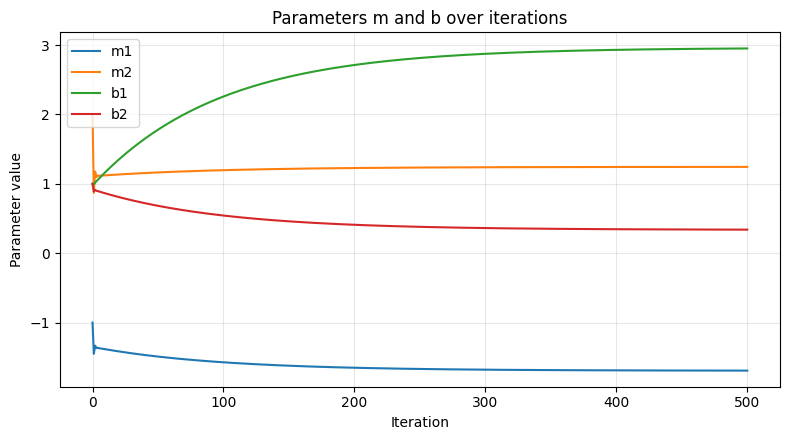

In [7]:
plot_parameters(history, filename="parameters_chart.png")

## 6. How the error changes

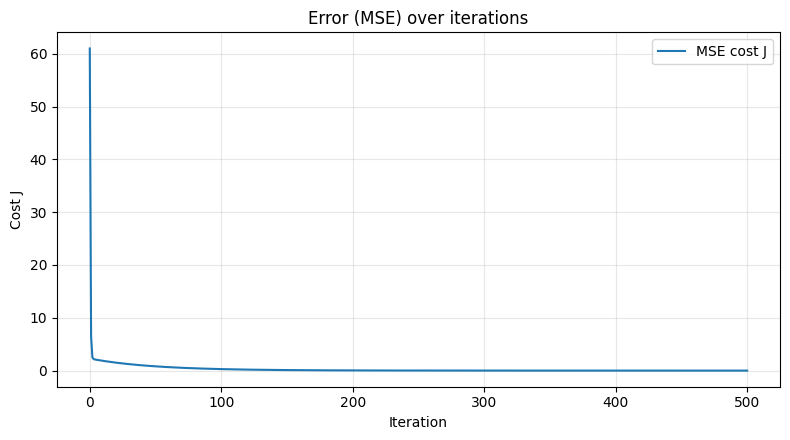

In [8]:
plot_cost(history, filename="cost_chart.png")

## 7. Predictions with the final m and b

In [9]:
y_hat = predict(X, m_final, b_final)
print("Final m =", m_final)
print("Final b =", b_final)
print("Predictions y_hat =", y_hat)
print("Actual y          =", Y)
print(f"Cost: start = {history['cost'][0]:.4f}  ->  end = {history['cost'][-1]:.6f}")
print("Cost fell at every iteration:", bool(np.all(np.diff(history['cost']) <= 0)))

Final m = [-1.69273666  1.24351723]
Final b = [2.95071776 0.33913639]
Predictions y_hat = [4.98853278 6.003362  ]
Actual y          = [5. 6.]
Cost: start = 61.0000  ->  end = 0.000071
Cost fell at every iteration: True


## 8. Trend

*(Rewrite in your own words before presenting.)*

- The cost falls at every iteration, quickly at first and then more slowly, so the updates are moving m and b in a direction that reduces the error.
- Early on the gradients are large, so the parameters change a lot. As the predictions get closer to y, the gradients shrink and the steps get smaller.
- The model has 4 parameters (m1, m2, b1, b2) and only 2 data points, so many parameter values fit the data almost perfectly. The final m and b depend on the starting values and the learning rate.
- The learning rate matters: for this data, values above about 0.0157 make the cost grow instead of shrink.